# Final study report evidence and rendering

Verify the final report against saved nested evaluation artifacts, produce its figures, and render a standalone HTML copy. This notebook does not fit models, tune thresholds, remove windows or alter the completed run. All calculations and plotting are contained here. Source prose lives in `docs/final-study-report.md`; output goes into a fresh directory under ignored `reports/portfolio-v2/final-study-report/`.

In [1]:
import base64
import hashlib
import html
import json
import re
from datetime import UTC, datetime
from pathlib import Path

import matplotlib.pyplot as plt
import mistune
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RUN = ROOT / "data/processed/portfolio-v2/plan001-real-20261108"
R = RUN / "full/real-20261109-v1/results"
SOURCE = ROOT / "docs/final-study-report.md"
OUT = (
    ROOT
    / "reports/portfolio-v2/final-study-report"
    / datetime.now(UTC).strftime("%Y%m%dT%H%M%S%fZ")
)
OUT.mkdir(parents=True, exist_ok=False)
manifest = json.loads((R / "manifest.json").read_text())
assert manifest["status"] == "complete" and not manifest["synthetic"]
for name, expected in manifest["artifacts"].items():
    assert hashlib.sha256((R / name).read_bytes()).hexdigest() == expected, name
assert (
    hashlib.sha256((ROOT / "notebooks/08_nested_evaluation.ipynb").read_bytes()).hexdigest()
    == manifest["context"]["runner_sha256"]
)
freeze = json.loads((RUN / "freeze/payload.json").read_text())
for name, expected in freeze["identity"]["source_hashes"].items():
    assert hashlib.sha256((ROOT / "notebooks" / name).read_bytes()).hexdigest() == expected
metrics = pd.read_csv(R / "metrics.csv")
trials = pd.read_parquet(R / "trial_results.parquet")
assert trials.groupby(["model", "outer_fold"]).size().eq(24).all()
assert len(trials) == 600
pred = pd.read_parquet(R / "outer_predictions.parquet")
oof = pd.read_parquet(R / "inner_oof_predictions.parquet")
choices = pd.DataFrame(json.loads((R / "selected_configurations.json").read_text()))
history = pd.read_parquet(R / "training_history.parquet")
report = SOURCE.read_text()
clean_report = report.replace("**", "")
order = ["logistic_regression", "linear_svm", "xgboost", "random_forest", "cnn"]
labels = {
    "logistic_regression": "Logistic regression",
    "linear_svm": "Adapted linear SVM",
    "xgboost": "XGBoost",
    "random_forest": "Random forest",
    "cnn": "CNN",
}
fixed = metrics.query("analysis == 'ablation' and level == 'fold_mean'").pivot(
    index="model", columns="feature_set", values="average_precision"
)
mean = metrics.query("analysis == 'tuned' and seed == 67 and level == 'fold_mean'").set_index(
    "model"
)
pooled = metrics.query("analysis == 'tuned' and seed == 67 and level == 'pooled'").set_index(
    "model"
)
folds = metrics.query("analysis == 'tuned' and seed == 67 and level == 'fold'").pivot(
    index="model", columns="identifier", values="average_precision"
)

## Check report tables against the completed run

The following checks compare the formatted values in the written report with unrounded saved metrics. Differences are calculated before rounding. The full trial table must account for all 24 candidates, five methods and five outer folds. Reference F1 is checked separately so the classification comparison cannot omit the always-positive strategy.

In [2]:
for model in ["logistic_regression", "random_forest", "xgboost"]:
    row = fixed.loc[model]
    line = f"| {labels[model]} | {row.A_F1:.3f} | {row.B_F2:.3f} | +{row.B_F2 - row.A_F1:.3f} |"
    assert line in clean_report, line
    line = (
        "| "
        + labels[model]
        + " | "
        + " | ".join(f"{row[key]:.3f}" for key in ["B_F2", "C_no_SDRR", "D_no_RMSSD", "E_no_pRR50"])
        + " |"
    )
    assert line in clean_report, line
report_labels = {
    **labels,
    "logistic_regression": "Logistic regression, F2",
    "xgboost": "XGBoost, F2",
    "random_forest": "Random forest, F2",
    "linear_svm": "Adapted literature linear SVM",
    "cnn": "Lightweight CNN, 100 Hz",
}
for model in order:
    values = [
        mean.loc[model, "average_precision"],
        mean.loc[model, "fold_ap_std"],
        pooled.loc[model, "average_precision"],
        pooled.loc[model, "roc_auc"],
    ]
    line = "| " + report_labels[model] + " | " + " | ".join(f"{v:.3f}" for v in values) + " |"
    assert line in clean_report, line
    line = "| " + labels[model] + " | " + " | ".join(f"{v:.3f}" for v in folds.loc[model]) + " |"
    assert line in clean_report, line
    values = pooled.loc[model, ["sensitivity", "specificity", "f1_score"]]
    line = "| " + labels[model] + " | " + " | ".join(f"{v:.3f}" for v in values) + " |"
    assert line in clean_report, line
reference = metrics.query(
    "analysis == 'reference' and model == 'constant_positive' and level == 'pooled'"
).iloc[0]
assert f"| Always predict apnea | 1.000 | 0.000 | {reference.f1_score:.3f} |" in report
for _, row in pd.read_csv(R / "uncertainty.csv").iterrows():
    interval = f"{row.lower:+.3f} to {row.upper:+.3f}".replace("-", "−")
    assert interval in report
primary_cnn = pred.query("analysis == 'tuned' and model == 'cnn' and seed == 67")
inner_cnn = oof.query("analysis == 'tuned' and model == 'cnn' and seed == 67")
transfer = []
for fold, part in primary_cnn.groupby("outer_fold"):
    inner = inner_cnn[inner_cnn.outer_fold.eq(fold)]
    transfer.append(
        dict(
            fold=int(fold) + 1,
            threshold=part.threshold.iloc[0],
            inner_positive=inner.prediction.mean(),
            outer_positive=part.prediction.mean(),
        )
    )
transfer = pd.DataFrame(transfer)
assert primary_cnn.groupby("outer_fold").prediction.mean().eq(1).sum() == 2
selected = choices.query("analysis == 'tuned' and model == 'cnn' and seed == 67")
assert selected.outer_epochs.tolist() == [1, 1, 3, 2, 1]
assert sum(epoch == 1 for epochs in selected.calibrated_epochs for epoch in epochs) == 7
print(
    "Report RQ1, primary, fold, pooled, reference and uncertainty tables agree with saved results."
)
display(fixed.round(3), mean[["average_precision", "fold_ap_std"]].round(3), transfer)

Report RQ1, primary, fold, pooled, reference and uncertainty tables agree with saved results.


feature_set,A_F1,B_F2,C_no_SDRR,D_no_RMSSD,E_no_pRR50
model,,,,,
logistic_regression,0.401,0.650,0.357,0.521,0.668
random_forest,0.400,0.507,0.355,0.489,0.519
xgboost,0.390,0.531,0.363,0.503,0.545


,average_precision,fold_ap_std
model,,
cnn,0.474,0.101
linear_svm,0.603,0.171
logistic_regression,0.646,0.137
random_forest,0.502,0.098
xgboost,0.540,0.136


,fold,threshold,inner_positive,outer_positive
0,1,0.424929,0.594673,0.758060
1,2,0.286781,0.507931,0.407255
2,3,0.368988,0.516523,0.267239
3,4,0.246968,0.999773,1.000000
4,5,0.240311,0.855281,1.000000


## Figures for the final report

All five figures are derived from saved artifacts. AP points show fold variation, not independent replications. Training curves show observed loss, not a claim that longer training would improve held-out performance. Source-signal examples retain physical units and show neighboring context.

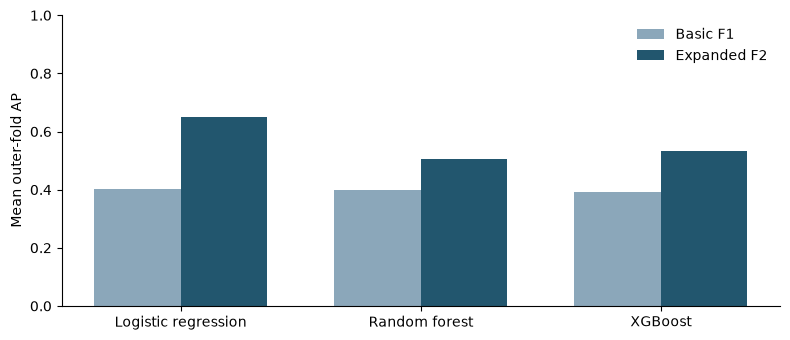

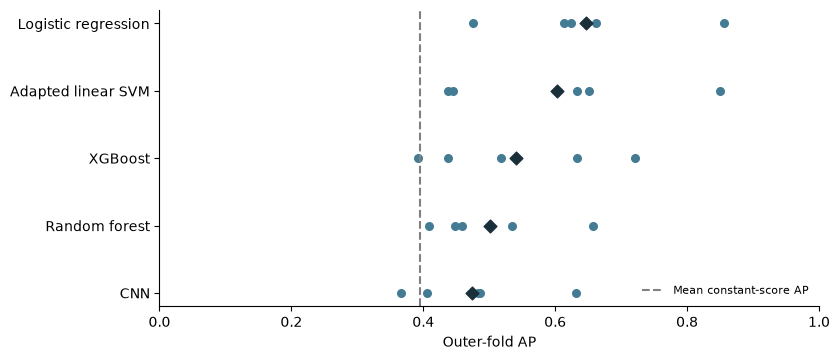

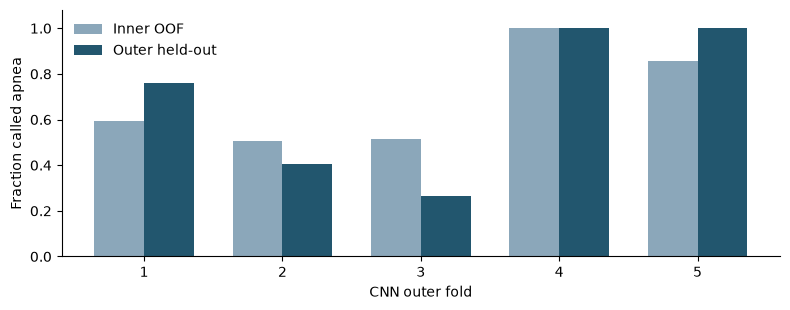

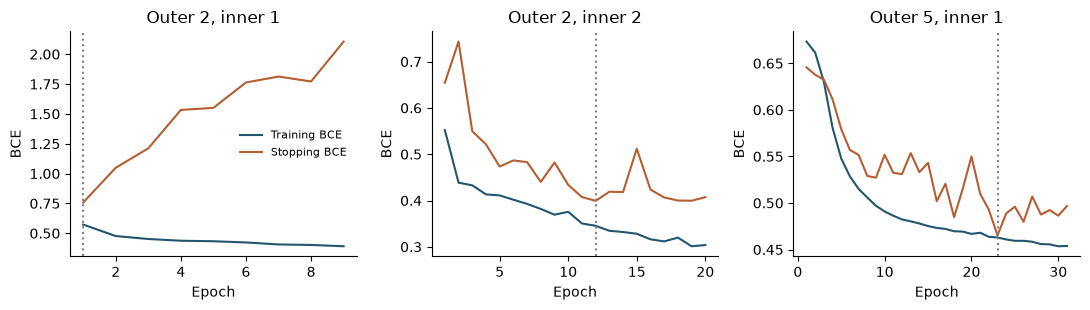

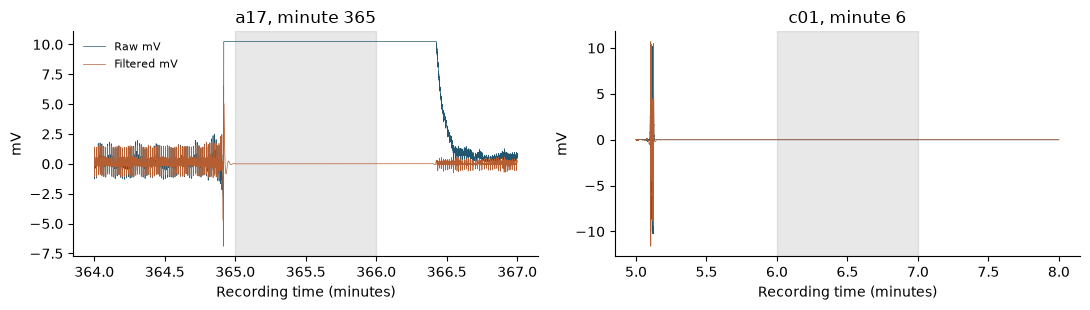

In [3]:
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
figures = {}


def save_figure(key, fig, caption, alt):
    fig.tight_layout()
    path = OUT / f"{key}.png"
    fig.savefig(path, dpi=160, bbox_inches="tight")
    figures[key] = dict(path=path, caption=caption, alt=alt)
    plt.show()
    plt.close(fig)


fig, ax = plt.subplots(figsize=(8, 3.5))
x = np.arange(3)
models = ["logistic_regression", "random_forest", "xgboost"]
ax.bar(x - 0.18, fixed.loc[models, "A_F1"], width=0.36, label="Basic F1", color="#8ba7ba")
ax.bar(x + 0.18, fixed.loc[models, "B_F2"], width=0.36, label="Expanded F2", color="#22566e")
ax.set(xticks=x, xticklabels=[labels[m] for m in models], ylabel="Mean outer-fold AP", ylim=(0, 1))
ax.legend(frameon=False)
save_figure(
    "rq1",
    fig,
    "Figure 1. Adding RR variability improved mean AP under fixed classifier settings.",
    "Bars compare basic F1 and expanded F2 mean AP for three classical classifiers.",
)

fig, ax = plt.subplots(figsize=(8.5, 3.7))
for i, model in enumerate(order):
    ax.scatter(folds.loc[model], np.full(5, i), color="#437b93", s=30)
    ax.scatter(mean.loc[model, "average_precision"], i, marker="D", color="#192f3a", s=42)
ax.axvline(0.395293, color="gray", linestyle="--", label="Mean constant-score AP")
ax.set(yticks=range(5), yticklabels=[labels[m] for m in order], xlabel="Outer-fold AP", xlim=(0, 1))
ax.invert_yaxis()
ax.legend(frameon=False, loc="lower right", fontsize=8)
save_figure(
    "rq2",
    fig,
    "Figure 2. Dots show the five folds; diamonds show their means. Spread is "
    "substantial and ordering changes across folds.",
    "Fold AP dot plot shows logistic regression leading on average and wide "
    "variability across held-out folds.",
)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(
    transfer.fold - 0.18, transfer.inner_positive, width=0.36, label="Inner OOF", color="#8ba7ba"
)
ax.bar(
    transfer.fold + 0.18,
    transfer.outer_positive,
    width=0.36,
    label="Outer held-out",
    color="#22566e",
)
ax.set(xlabel="CNN outer fold", ylabel="Fraction called apnea", ylim=(0, 1.08), xticks=range(1, 6))
ax.legend(frameon=False)
save_figure(
    "thresholds",
    fig,
    "Figure 3. CNN thresholds were already permissive in folds 4 and 5 before "
    "being applied to held-out groups.",
    "Inner and outer positive prediction rates by CNN fold, with outer folds four"
    " and five at one hundred percent.",
)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, (fold, inner) in zip(axes, [(1, 0), (1, 1), (4, 0)], strict=True):
    choice = selected[selected.outer_fold.eq(fold)].iloc[0]
    task = f"outer-{fold}/tuned/cnn/candidate-{int(choice.candidate):02d}-inner-{inner}"
    part = history[history.task.eq(task) & history.stage.eq("calibration")]
    ax.plot(part.epoch, part.train_loss, label="Training BCE", color="#22566e")
    ax.plot(part.epoch, part.stop_loss, label="Stopping BCE", color="#b45e32")
    ax.axvline(choice.calibrated_epochs[inner], color="gray", linestyle=":")
    ax.set(title=f"Outer {fold + 1}, inner {inner + 1}", xlabel="Epoch", ylabel="BCE")
axes[0].legend(frameon=False, fontsize=8)
save_figure(
    "curves",
    fig,
    "Figure 4. Three selected calibration histories illustrate early divergence "
    "and later improvement on different groups. Dotted lines mark selected "
    "epochs; these examples use unweighted training BCE.",
    "Three learning curves show a stopping loss increase, improvement to epoch "
    "twelve, and improvement to epoch twenty-three.",
)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, (record, minute) in zip(axes, [("a17", 365), ("c01", 6)], strict=True):
    with np.load(ROOT / "data/processed/phase1/waveforms" / f"{record}.npz") as source:
        raw, filtered = source["raw"], source["filtered"]
    a, b = (minute - 1) * 6000, (minute + 2) * 6000
    assert np.ptp(raw[minute * 6000 : (minute + 1) * 6000]) == 0
    t = np.arange(a, b) / 6000
    ax.plot(t, raw[a:b], linewidth=0.5, label="Raw mV", color="#22566e")
    ax.plot(t, filtered[a:b], linewidth=0.5, label="Filtered mV", color="#b45e32")
    ax.axvspan(minute, minute + 1, color="gray", alpha=0.18)
    ax.set(title=f"{record}, minute {minute}", xlabel="Recording time (minutes)", ylabel="mV")
axes[0].legend(frameon=False, fontsize=8)
save_figure(
    "signals",
    fig,
    "Figure 5. Shading marks two of the 17 constant-source minutes. Filtering "
    "removes a constant baseline; it did not create the absence of raw waveform "
    "variation.",
    "Original and filtered signals around two constant intervals, shaded in gray.",
)

## Render a portable report

The HTML embeds every figure and uses no external fonts or scripts. Repository references remain named resources rather than links to private filesystem paths. The shared copy contains the report text, tables and figures; detailed notebooks and data remain separate repository resources.

In [4]:
markdown = mistune.create_markdown(escape=False, plugins=["table"])
report_for_html = report
for key in figures:
    report_for_html = report_for_html.replace(
        f"![Study evidence: {key}](../reports/figures/{key}.png)", f"<!-- FIGURE {key} -->"
    )
body = markdown(report_for_html)
for key, item in figures.items():
    encoded = base64.b64encode(item["path"].read_bytes()).decode()
    figure_html = (
        '<figure><img src="data:image/png;base64,'
        + encoded
        + '" alt="'
        + html.escape(item["alt"])
        + '">'
        "<figcaption>" + html.escape(item["caption"]) + "</figcaption></figure>"
    )
    marker = f"<!-- FIGURE {key} -->"
    assert marker in body, key
    body = body.replace(marker, figure_html)
assert "<!-- FIGURE" not in body


# Repository links are supplementary; report content and figures are embedded.
def resolve_link(match):
    target = match.group(1)
    if target.startswith(("https://", "http://", "#", "data:")):
        return match.group(0)
    path = (SOURCE.parent / target).resolve()
    assert path.exists(), target
    return (
        'class="repository-reference" title="Repository resource: '
        + html.escape(target, quote=True)
        + '"'
    )


body = re.sub(r'href="([^"]+)"', resolve_link, body)
css = """
:root { color-scheme: light; }
body { margin: 0; background: #f4f5f5; color: #202b31; font: 16px/1.65 Georgia, serif; }
main { max-width: 960px; margin: 36px auto; padding: 48px 60px; background: white; }
h1,h2,h3,th { font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', sans-serif; }
h1 { font-size: 2.25rem; line-height: 1.2; margin-top: 0; color: #183d50; }
h2 { font-size: 1.45rem; margin-top: 2.2em; border-bottom: 1px solid #d8e1e5; padding-bottom:
.35em; }
h3 { font-size: 1.1rem; margin-top: 1.7em; }
a { color: #185d7b; } p { margin: .9em 0; }
table { width: 100%; border-collapse: collapse; font: .84rem/1.45 -apple-system, sans-serif;
margin: 1.5em 0; }
th { background: #edf3f6; text-align: left; } th,td { padding: 9px 10px; border-bottom: 1px
solid #d9e0e3; }
tr { break-inside: avoid; } figure { margin: 1.8em 0; break-inside: avoid; }
img { width: 100%; height: auto; } figcaption { font: .85rem/1.5 -apple-system, sans-serif;
color: #44565f; }
code { font-size: .8em; overflow-wrap: anywhere; } li { margin: .6em 0; }
@media(max-width: 700px) { main { margin: 0; padding: 24px 18px; } table { font-size: .72rem; }
th,td { padding: 6px; } }
@media print { @page { size: A4; margin: 16mm; } body { background:white; font-size:10.5pt; }
main { max-width:none; margin:0; padding:0; } h1 { font-size:23pt; } h2 { font-size:15pt;
break-after:avoid; } h3 { break-after:avoid; } table { font-size:8pt; } a { color:inherit;
text-decoration:none; } }"""
page = (
    '<!doctype html><html lang="en"><head><meta charset="utf-8"><meta '
    'name="viewport" content="width=device-width, initial-scale=1"><title>RR '
    "interval features and a lightweight CNN for sleep apnea "
    "classification</title><style>"
    + css
    + "</style></head><body><main>"
    + body
    + "</main></body></html>"
)
(OUT / "final-study-report.html").write_text(page)
(OUT / "final-study-report.md").write_text(report)
for name, table in {
    "fixed_features": fixed,
    "primary_means": mean,
    "primary_pooled": pooled,
    "primary_folds": folds,
    "cnn_thresholds": transfer,
}.items():
    table.to_csv(OUT / f"{name}.csv")
provenance = dict(
    created_utc=datetime.now(UTC).isoformat(),
    report_sha256=hashlib.sha256(SOURCE.read_bytes()).hexdigest(),
    notebook_sha256=hashlib.sha256(
        (ROOT / "notebooks/12_final_report.ipynb").read_bytes()
    ).hexdigest(),
    results_manifest_sha256=hashlib.sha256((R / "manifest.json").read_bytes()).hexdigest(),
    freeze_id=manifest["context"]["freeze_id"],
    status="complete",
)
(OUT / "manifest.json").write_text(json.dumps(provenance, indent=2) + "\n")
print("Verified and rendered:", OUT / "final-study-report.html")

Verified and rendered: <project-root>/reports/portfolio-v2/final-study-report/20261110T060513411445Z/final-study-report.html
